In [1]:
import numpy as np
import tensorflow as tf
import pandas as pd

In [2]:
# Load the TFLite model and allocate tensors.
interpreter = tf.lite.Interpreter(model_path="MassSpringDamper_OpNN.tflite")
interpreter.allocate_tensors()

# Get input and output tensors.
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

In [3]:
X = pd.read_csv('../data/test/case_001.csv').to_numpy(dtype=np.float32)
x = [np.take(X, [0,1], axis=1), np.take(X, [2], axis=1)]
y = np.take(X, [3,4], axis=1)

In [7]:
for i, inp in enumerate(input_details):
    interpreter.resize_tensor_input(inp['index'], x[i].shape, strict=True)
    interpreter.allocate_tensors()
    interpreter.set_tensor(inp['index'], x[i])
interpreter.invoke()
y_pred = interpreter.get_tensor(output_details[0]['index'])

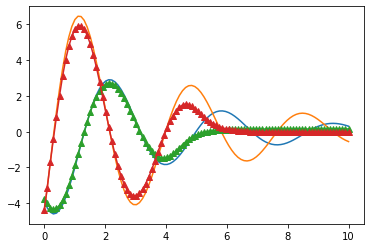

In [8]:
from matplotlib import pyplot as plt
plt.plot(x[1], y)
plt.plot(x[1], y_pred, '^-')